# AlphaWind data analysis

## 1. Introduction

### Data overview

| Dataset              | Description                             | Granularity            |
|----------------------|-----------------------------------------|------------------------|
| production.csv       | Energy production per turbine           | 10 minutes             |
| weather.csv          | Wind speed measurements                 | Park level, 10 minutes |
| stops_log.csv        | Operational stop and event records      | Event level            |
| turbine_metadata.csv | Turbine information and service history | Turbine level          |

All datasets cover the same 7-day period.

### Variables

production.csv
- timestamp
- turbine_id
- energy_kwh

stops_log.csv
- timestamp_start
- timestamp_end
- turbine_id
- stop_code
- comment

turbine_metadata.csv
- turbine_id
- park
- country
- model
- last_service_days_ago

weather.csv
- timestamp
- wind_speed_ms

### Data limitations

The stop log is not fully reliable. It may contain:

- Missing event end timestamps.
- Duplicate event records.
- Incorrect or extended event durations.
- Incomplete reporting of park-level events across individual turbines.

### Goal of the analysis

Investigate the available data, identify the main drivers of production losses and develop an understanding of what happened during the period.

### Key findings

## 2. Importing data

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import duckdb
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

In [2]:
df_prod = pd.read_csv("./production.csv", parse_dates=["timestamp"])
df_prod.head()

,timestamp,turbine_id,energy_kwh
0,2026-03-01 00:00:00,T01,81.98
1,2026-03-01 00:10:00,T01,104.79
2,2026-03-01 00:20:00,T01,94.30
3,2026-03-01 00:30:00,T01,132.86
4,2026-03-01 00:40:00,T01,237.53


In [3]:
df_stops = pd.read_csv("./stops_log.csv", parse_dates=["timestamp_start", "timestamp_end"])
df_stops.head()

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
0,2026-03-02 01:30:00,2026-03-02 03:00:00,T02,FLT,Hydraulic technical fault #1
1,2026-03-02 06:40:00,2026-03-02 08:10:00,T04,FLT,Hydraulic technical fault #1
2,2026-03-03 11:50:00,2026-03-03 14:50:00,T06,MTN,Scheduled maintenance
3,2026-03-03 23:20:00,2026-03-04 00:50:00,T03,FLT,Hydraulic technical fault #1
4,2026-03-04 09:00:00,2026-03-04 11:00:00,T01,GRD,Park-level grid limitation


| Code | Meaning                 | Scope         |
|------|-------------------------|---------------|
| WND  | Extreme wind conditions | Park level    |
| GRD  | Grid limitation         | Park level    |
| FLT  | Technical turbine fault | Turbine level |
| MTN  | Scheduled maintenance   | Turbine level |

In [4]:
df_turb = pd.read_csv("./turbine_metadata.csv")
df_turb.sort_values(by="last_service_days_ago")

,turbine_id,park,country,model,last_service_days_ago
2,T03,AlphaWind,LT,V112,5
0,T01,AlphaWind,LT,V112,12
4,T05,AlphaWind,LT,V112,18
1,T02,AlphaWind,LT,V112,40
5,T06,AlphaWind,LT,V112,65
3,T04,AlphaWind,LT,V112,120


In [5]:
df_weather = pd.read_csv("./weather.csv", parse_dates=["timestamp"])
df_weather.head()

,timestamp,wind_speed_ms
0,2026-03-01 00:00:00,8.33
1,2026-03-01 00:10:00,9.00
2,2026-03-01 00:20:00,8.78
3,2026-03-01 00:30:00,9.67
4,2026-03-01 00:40:00,11.85


## 3. Data quality

Checking if the data is complete

In [6]:
dfs = {
    "df_prod": df_prod,
    "df_stops": df_stops,
    "df_turb": df_turb,
    "df_weather": df_weather,
}

In [7]:
for name, df in dfs.items():
    print(f"Dataframe: {name}")
    print(f"Shape: {df.shape}")
    print(f"Duplicate rows: {df.duplicated().sum()}")
    print("Missing values per column:")
    print(df.isna().sum()[df.isna().sum() > 0])
    print()

Dataframe: df_prod
Shape: (6048, 3)
Duplicate rows: 0
Missing values per column:
Series([], dtype: int64)

Dataframe: df_stops
Shape: (38, 5)
Duplicate rows: 1
Missing values per column:
timestamp_end    4
dtype: int64

Dataframe: df_turb
Shape: (6, 5)
Duplicate rows: 0
Missing values per column:
Series([], dtype: int64)

Dataframe: df_weather
Shape: (1008, 2)
Duplicate rows: 0
Missing values per column:
Series([], dtype: int64)



- Duplicate rows in stops dataframe, dropping these rows
- Missing values in the stop end

Checking if the data types are correct

In [8]:
for name, df in dfs.items():
    print(f"Dataframe: {name}")
    print(f"Data types:\n{df.dtypes}")
    print()

Dataframe: df_prod
Data types:
timestamp     datetime64[us]
turbine_id               str
energy_kwh           float64
dtype: object

Dataframe: df_stops
Data types:
timestamp_start    datetime64[us]
timestamp_end      datetime64[us]
turbine_id                    str
stop_code                     str
comment                       str
dtype: object

Dataframe: df_turb
Data types:
turbine_id                 str
park                       str
country                    str
model                      str
last_service_days_ago    int64
dtype: object

Dataframe: df_weather
Data types:
timestamp        datetime64[us]
wind_speed_ms           float64
dtype: object



In [9]:
df_stops = df_stops.drop_duplicates()

Checking the length of the data frames - production and weather data should have 7 days x 1440 minutes / 10 = 1008 rows of data

In [10]:
len(df_weather)

1008

In [11]:
df_prod.groupby("turbine_id").size()

turbine_id
T01    1008
T02    1008
T03    1008
T04    1008
T05    1008
T06    1008
dtype: int64

Checking the maximum energy generated per 10mins for each turbine

In [12]:
df_prod.groupby(by="turbine_id").max()

,timestamp,energy_kwh
turbine_id,,
T01,2026-03-07 23:50:00,250.00
T02,2026-03-07 23:50:00,246.25
T03,2026-03-07 23:50:00,251.25
T04,2026-03-07 23:50:00,225.00
T05,2026-03-07 23:50:00,252.50
T06,2026-03-07 23:50:00,247.50


Energy generated versus the wind speed + stops marked

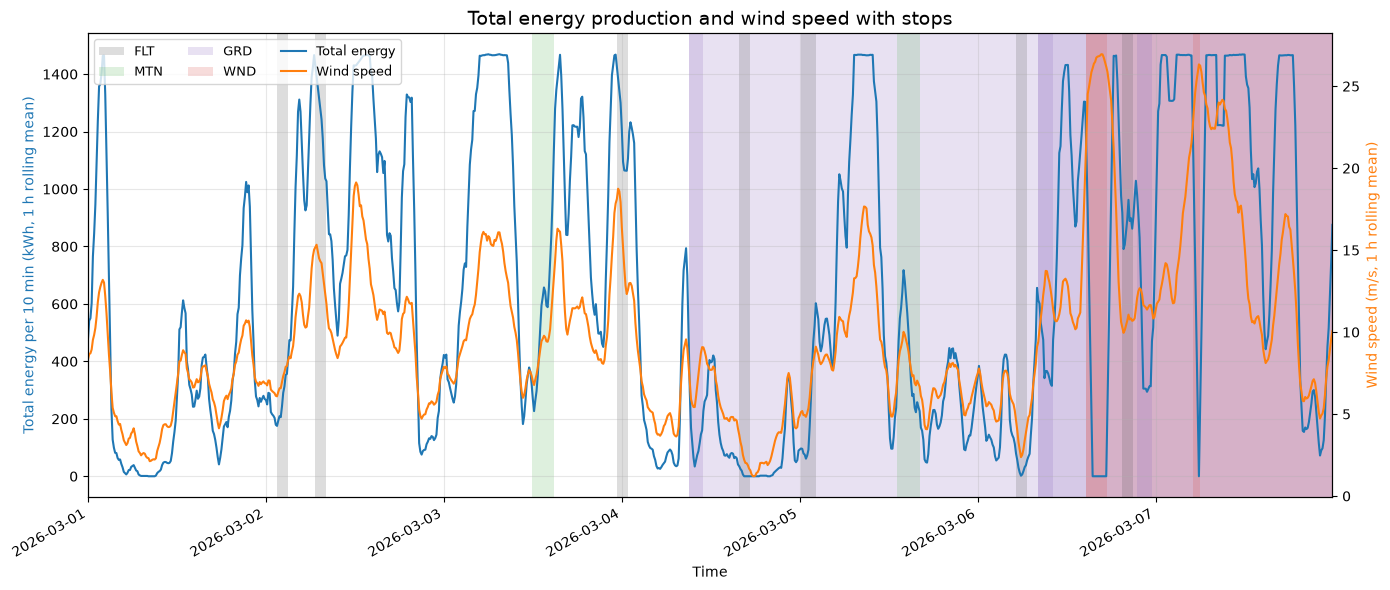

In [13]:
STOP_COLORS = {"WND": "#d9534f", "GRD": "#8e6bbf", "MTN": "#5cb85c", "FLT": "#555555"}

df_prod["timestamp"] = pd.to_datetime(df_prod["timestamp"])
df_weather["timestamp"] = pd.to_datetime(df_weather["timestamp"])

total = df_prod.groupby("timestamp")["energy_kwh"].sum().sort_index()
wind = df_weather.set_index("timestamp")["wind_speed_ms"].sort_index()

total_1h = total.rolling("1h").mean()
wind_1h = wind.rolling("1h").mean()

stops = df_stops.drop_duplicates(subset=["timestamp_start", "stop_code", "turbine_id"]).copy()
stops[["timestamp_start", "timestamp_end"]] = stops[["timestamp_start", "timestamp_end"]].apply(pd.to_datetime)
stops["timestamp_end"] = stops["timestamp_end"].fillna(total.index.max())
stops = stops.drop_duplicates(subset=["timestamp_start", "timestamp_end", "stop_code"])

fig, ax1 = plt.subplots(figsize=(14, 6))

labelled = set()
for _, s in stops.iterrows():
    code = s["stop_code"]
    ax1.axvspan(s["timestamp_start"], s["timestamp_end"],
                color=STOP_COLORS.get(code, "grey"), alpha=0.2, linewidth=0,
                label=code if code not in labelled else None)   # label each code once
    labelled.add(code)

ax1.plot(total_1h.index, total_1h.values, color="tab:blue", linewidth=1.5, label="Total energy")
ax1.set_ylabel("Total energy per 10 min (kWh, 1 h rolling mean)", color="tab:blue")
ax1.set_xlabel("Time")

ax2 = ax1.twinx()
ax2.plot(wind_1h.index, wind_1h.values, color="tab:orange", linewidth=1.5, label="Wind speed")
ax2.set_ylabel("Wind speed (m/s, 1 h rolling mean)", color="tab:orange")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", ncol=3, fontsize=9)

ax1.set_xlim(total.index.min(), total.index.max())
ax1.set_title("Total energy production and wind speed with stops", fontsize=14)
ax1.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 4. Data cleaning

Fixing missing end marks - all of them are about park level stops, so should be for all turbines

In [14]:
df_stops[df_stops["timestamp_end"].isna()]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
9,2026-03-04 09:00:00,NaT,T06,GRD,Park-level grid limitation
15,2026-03-06 08:10:00,NaT,T03,GRD,Park-level grid limitation
22,2026-03-06 14:40:00,NaT,T04,WND,High wind shutdown
24,2026-03-06 14:40:00,NaT,T06,WND,High wind shutdown


In [15]:
df_stops[df_stops["timestamp_start"] == "2026-03-04 09:00:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
4,2026-03-04 09:00:00,2026-03-04 11:00:00,T01,GRD,Park-level grid limitation
5,2026-03-04 09:00:00,2026-03-04 11:00:00,T02,GRD,Park-level grid limitation
6,2026-03-04 09:00:00,2026-03-04 11:00:00,T03,GRD,Park-level grid limitation
7,2026-03-04 09:00:00,2026-03-04 11:00:00,T04,GRD,Park-level grid limitation
8,2026-03-04 09:00:00,2026-03-04 11:00:00,T05,GRD,Park-level grid limitation
9,2026-03-04 09:00:00,NaT,T06,GRD,Park-level grid limitation


In [16]:
mask = (df_stops["timestamp_start"] == "2026-03-04 09:00:00") & (df_stops["turbine_id"] == "T06")
df_stops.loc[mask, "timestamp_end"] = pd.Timestamp("2026-03-04 11:00:00")

In [17]:
df_stops[df_stops["timestamp_start"] == "2026-03-04 09:00:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
4,2026-03-04 09:00:00,2026-03-04 11:00:00,T01,GRD,Park-level grid limitation
5,2026-03-04 09:00:00,2026-03-04 11:00:00,T02,GRD,Park-level grid limitation
6,2026-03-04 09:00:00,2026-03-04 11:00:00,T03,GRD,Park-level grid limitation
7,2026-03-04 09:00:00,2026-03-04 11:00:00,T04,GRD,Park-level grid limitation
8,2026-03-04 09:00:00,2026-03-04 11:00:00,T05,GRD,Park-level grid limitation
9,2026-03-04 09:00:00,2026-03-04 11:00:00,T06,GRD,Park-level grid limitation


In [18]:
df_stops[df_stops["timestamp_start"] == "2026-03-06 08:10:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
14,2026-03-06 08:10:00,2026-03-06 10:10:00,T01,GRD,Park-level grid limitation
15,2026-03-06 08:10:00,NaT,T03,GRD,Park-level grid limitation
16,2026-03-06 08:10:00,2026-03-06 10:10:00,T04,GRD,Park-level grid limitation
17,2026-03-06 08:10:00,2026-03-06 10:10:00,T05,GRD,Park-level grid limitation
18,2026-03-06 08:10:00,2026-03-06 10:10:00,T06,GRD,Park-level grid limitation


In [19]:
mask = (df_stops["timestamp_start"] == "2026-03-06 08:10:00") & (df_stops["turbine_id"] == "T03")
df_stops.loc[mask, "timestamp_end"] = pd.Timestamp("2026-03-06 10:10:00")

Was the T02 turbine also stopped during this time?

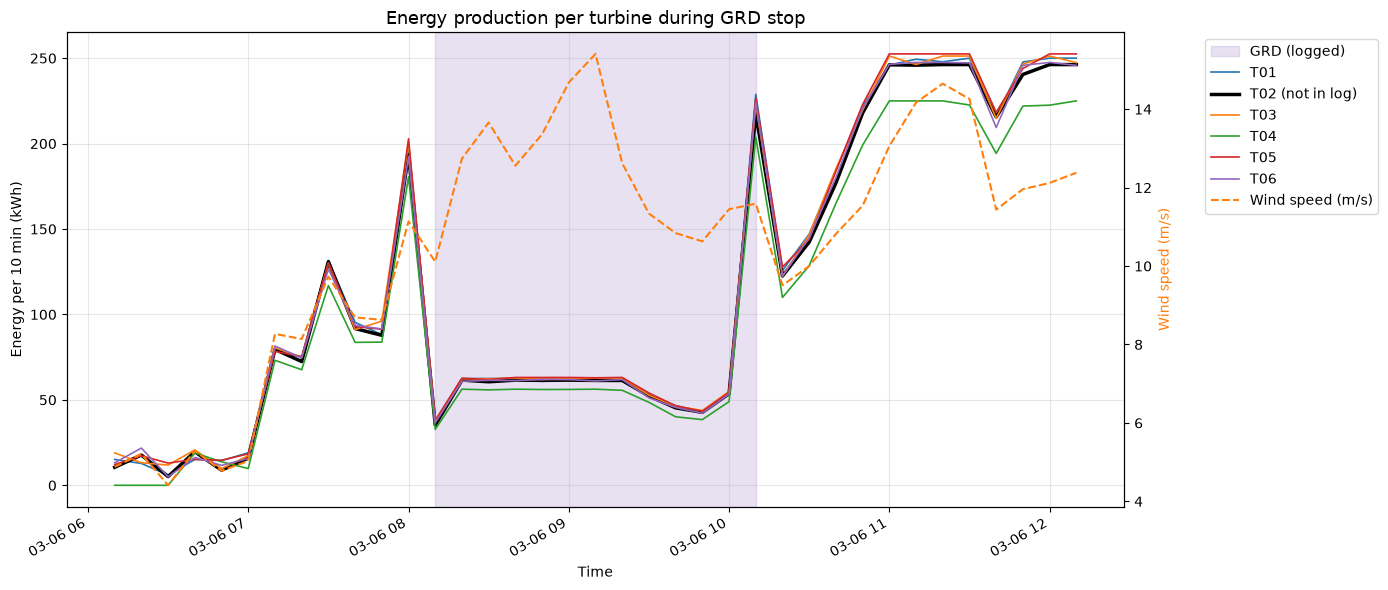

In [20]:
start = pd.Timestamp("2026-03-06 08:10:00")
end = pd.Timestamp("2026-03-06 10:10:00")
margin = pd.Timedelta("2h")

window = df_prod[df_prod["timestamp"].between(start - margin, end + margin)]
wind = df_weather[df_weather["timestamp"].between(start - margin, end + margin)]

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.axvspan(start, end, color="#8e6bbf", alpha=0.2, label="GRD (logged)")

for tid, t in window.groupby("turbine_id"):
    highlight = tid == "T02"
    ax1.plot(t["timestamp"], t["energy_kwh"],
             linewidth=2.5 if highlight else 1.2,
             color="black" if highlight else None,
             label=f"{tid}" + (" (not in log)" if highlight else ""))

ax1.set_ylabel("Energy per 10 min (kWh)")
ax1.set_xlabel("Time")

ax2 = ax1.twinx()
ax2.plot(wind["timestamp"], wind["wind_speed_ms"], color="tab:orange", linestyle="--",
         linewidth=1.5, label="Wind speed (m/s)")
ax2.set_ylabel("Wind speed (m/s)", color="tab:orange")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", bbox_to_anchor=(1.07, 1))

ax1.set_title("Energy production per turbine during GRD stop", fontsize=13)
ax1.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Adding the stop for the T02 turbine as well

In [21]:
new_row = pd.DataFrame([{
    "timestamp_start": pd.Timestamp("2026-03-06 08:10:00"),
    "timestamp_end": pd.Timestamp("2026-03-06 10:10:00"),
    "turbine_id": "T02",
    "stop_code": "GRD",
    "comment": "Park-level grid limitation (added: missing from log)",
}])

df_stops = pd.concat([df_stops, new_row], ignore_index=True)
df_stops = df_stops.sort_values(["timestamp_start", "turbine_id"]).reset_index(drop=True)

In [22]:
df_stops[df_stops["timestamp_start"] == "2026-03-06 08:10:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
14,2026-03-06 08:10:00,2026-03-06 10:10:00,T01,GRD,Park-level grid limitation
15,2026-03-06 08:10:00,2026-03-06 10:10:00,T02,GRD,Park-level grid limitation (added: missing fro...
16,2026-03-06 08:10:00,2026-03-06 10:10:00,T03,GRD,Park-level grid limitation
17,2026-03-06 08:10:00,2026-03-06 10:10:00,T04,GRD,Park-level grid limitation
18,2026-03-06 08:10:00,2026-03-06 10:10:00,T05,GRD,Park-level grid limitation
19,2026-03-06 08:10:00,2026-03-06 10:10:00,T06,GRD,Park-level grid limitation


In [23]:
df_stops[df_stops["timestamp_start"] == "2026-03-06 14:40:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
20,2026-03-06 14:40:00,2026-03-06 17:30:00,T01,WND,High wind shutdown
21,2026-03-06 14:40:00,2026-03-06 17:30:00,T02,WND,High wind shutdown
22,2026-03-06 14:40:00,2026-03-06 17:30:00,T03,WND,High wind shutdown
23,2026-03-06 14:40:00,NaT,T04,WND,High wind shutdown
24,2026-03-06 14:40:00,2026-03-06 17:30:00,T05,WND,High wind shutdown
25,2026-03-06 14:40:00,NaT,T06,WND,High wind shutdown


In [24]:
mask = (df_stops["timestamp_start"] == "2026-03-06 14:40:00") & (df_stops["turbine_id"].isin(["T04", "T06"]))
df_stops.loc[mask, "timestamp_end"] = pd.Timestamp("2026-03-06 17:30:00")

In [25]:
df_stops[df_stops["timestamp_start"] == "2026-03-06 14:40:00"]

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
20,2026-03-06 14:40:00,2026-03-06 17:30:00,T01,WND,High wind shutdown
21,2026-03-06 14:40:00,2026-03-06 17:30:00,T02,WND,High wind shutdown
22,2026-03-06 14:40:00,2026-03-06 17:30:00,T03,WND,High wind shutdown
23,2026-03-06 14:40:00,2026-03-06 17:30:00,T04,WND,High wind shutdown
24,2026-03-06 14:40:00,2026-03-06 17:30:00,T05,WND,High wind shutdown
25,2026-03-06 14:40:00,2026-03-06 17:30:00,T06,WND,High wind shutdown


Redrawing the energy production and stops graph

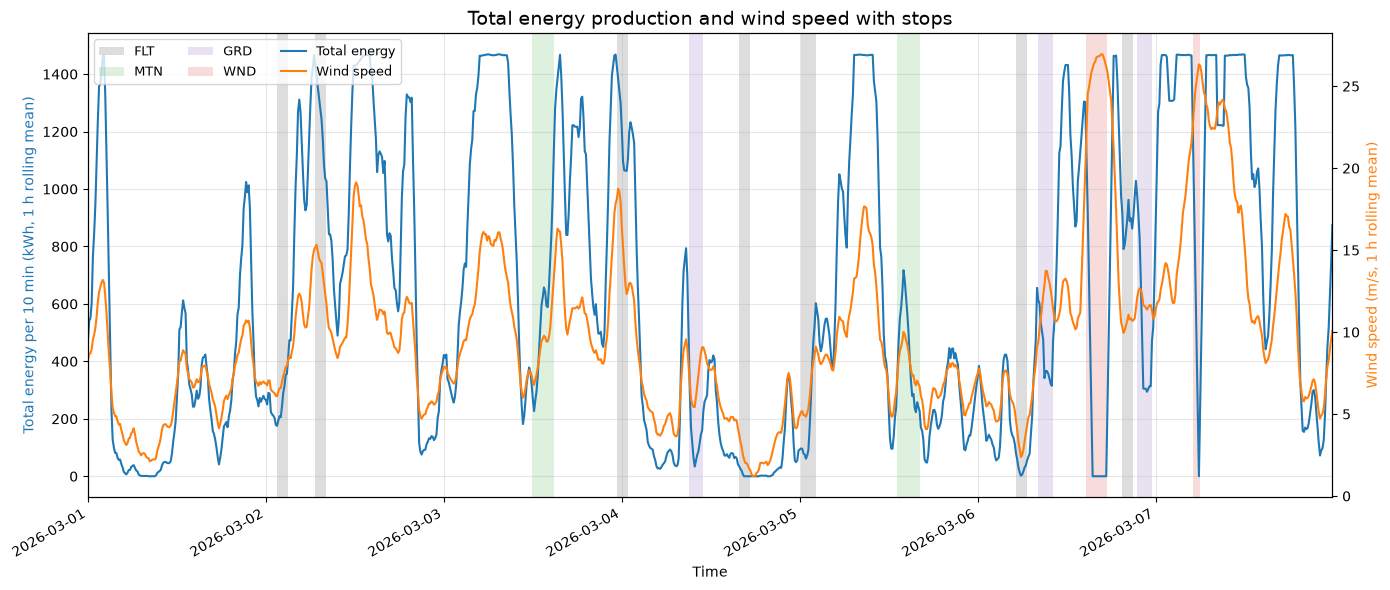

In [26]:
STOP_COLORS = {"WND": "#d9534f", "GRD": "#8e6bbf", "MTN": "#5cb85c", "FLT": "#555555"}

df_prod["timestamp"] = pd.to_datetime(df_prod["timestamp"])
df_weather["timestamp"] = pd.to_datetime(df_weather["timestamp"])

total = df_prod.groupby("timestamp")["energy_kwh"].sum().sort_index()
wind = df_weather.set_index("timestamp")["wind_speed_ms"].sort_index()

total_1h = total.rolling("1h").mean()
wind_1h = wind.rolling("1h").mean()

stops = df_stops.drop_duplicates(subset=["timestamp_start", "stop_code", "turbine_id"]).copy()
stops[["timestamp_start", "timestamp_end"]] = stops[["timestamp_start", "timestamp_end"]].apply(pd.to_datetime)
stops["timestamp_end"] = stops["timestamp_end"].fillna(total.index.max())
stops = stops.drop_duplicates(subset=["timestamp_start", "timestamp_end", "stop_code"])

fig, ax1 = plt.subplots(figsize=(14, 6))

labelled = set()
for _, s in stops.iterrows():
    code = s["stop_code"]
    ax1.axvspan(s["timestamp_start"], s["timestamp_end"],
                color=STOP_COLORS.get(code, "grey"), alpha=0.2, linewidth=0,
                label=code if code not in labelled else None)   # label each code once
    labelled.add(code)

ax1.plot(total_1h.index, total_1h.values, color="tab:blue", linewidth=1.5, label="Total energy")
ax1.set_ylabel("Total energy per 10 min (kWh, 1 h rolling mean)", color="tab:blue")
ax1.set_xlabel("Time")

ax2 = ax1.twinx()
ax2.plot(wind_1h.index, wind_1h.values, color="tab:orange", linewidth=1.5, label="Wind speed")
ax2.set_ylabel("Wind speed (m/s, 1 h rolling mean)", color="tab:orange")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", ncol=3, fontsize=9)

ax1.set_xlim(total.index.min(), total.index.max())
ax1.set_title("Total energy production and wind speed with stops", fontsize=14)
ax1.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Note: the stops due to low wind are not recorded, only due to high wind, intentional stops.

## 5. Expected energy production

To see how much energy was lost, first we have to see how much should be produced if everything goes right.

In [27]:
data = df_prod.merge(df_weather, on="timestamp", how="left")

MARGIN = pd.Timedelta("1h")
data["near_event"] = False
for _, s in df_stops.iterrows():
    end = s["timestamp_end"] if pd.notna(s["timestamp_end"]) else data["timestamp"].max()
    mask = ((data["turbine_id"] == s["turbine_id"]) &
            (data["timestamp"] >= s["timestamp_start"] - MARGIN) &
            (data["timestamp"] <= end + MARGIN))
    data.loc[mask, "near_event"] = True

CUT_IN = 3.0
clean = data[
    (~data["near_event"]) &
    (data["wind_speed_ms"] > CUT_IN) &
    (data["energy_kwh"] > 0)
]
print(f"Time intervals without events (plus margin): {len(clean)/len(data):.0%}")

Time intervals without events (plus margin): 79%


In [28]:
BIN = 0.5
clean = clean.assign(ws_bin=(clean["wind_speed_ms"] / BIN).round() * BIN)

curve = (clean.groupby("ws_bin")["energy_kwh"]
              .agg(expected_kwh="median", n="size")
              .reset_index())
curve = curve[curve["n"] >= 5]

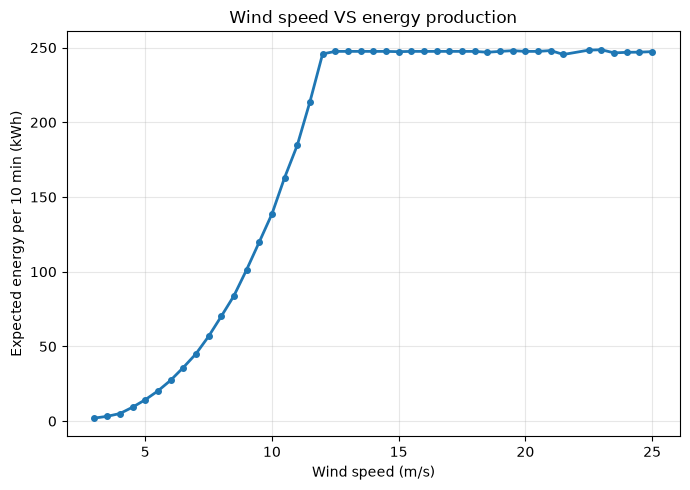

In [29]:
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(curve["ws_bin"], curve["expected_kwh"], marker="o", markersize=4, linewidth=2)

ax.set_xlabel("Wind speed (m/s)")
ax.set_ylabel("Expected energy per 10 min (kWh)")
ax.set_title("Wind speed VS energy production")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
RATED = clean["energy_kwh"].quantile(0.99)

def expected_energy(ws):
    e = np.interp(ws, curve["ws_bin"], curve["expected_kwh"])
    e = np.where(ws < CUT_IN, 0, e)
    e = np.where(ws >= curve["ws_bin"].max(), RATED, e)
    return np.minimum(e, RATED)

data["expected_kwh"] = expected_energy(data["wind_speed_ms"].values)

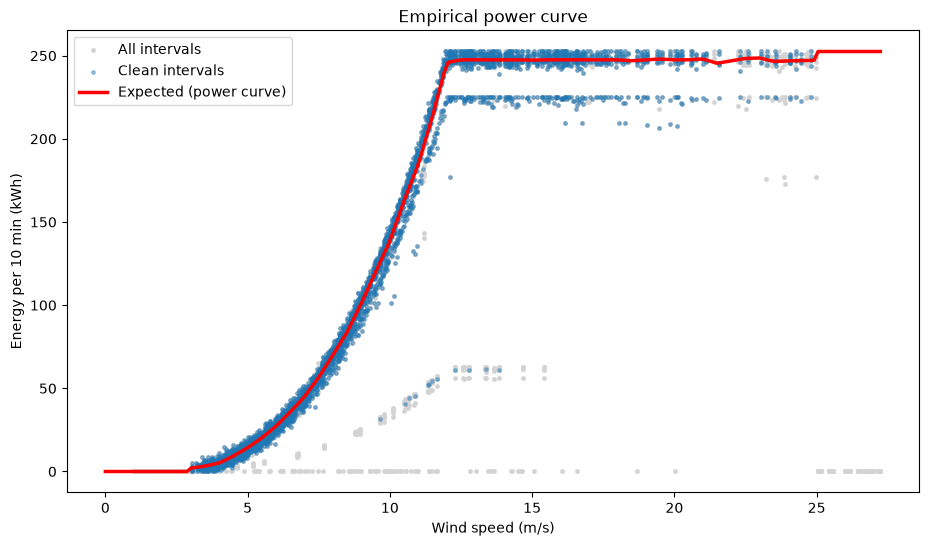

In [31]:
ws_grid = np.linspace(0, data["wind_speed_ms"].max(), 200)

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(data["wind_speed_ms"], data["energy_kwh"], s=6, color="lightgrey", label="All intervals")
ax.scatter(clean["wind_speed_ms"], clean["energy_kwh"], s=6, color="tab:blue", alpha=0.4, label="Clean intervals")
ax.plot(ws_grid, expected_energy(ws_grid), color="red", linewidth=2.5, label="Expected (power curve)")
ax.set_xlabel("Wind speed (m/s)")
ax.set_ylabel("Energy per 10 min (kWh)")
ax.set_title("Empirical power curve")
ax.legend()
plt.show()

In [32]:
c = data.loc[clean.index]
residual = c["energy_kwh"] - c["expected_kwh"]

print(f"Mean residual: {residual.mean():.1f} kWh")
print(f"Typical error (median absolute): {residual.abs().median():.1f} kWh per 10 min")
print(f"Actual and expected on clean data: {c['energy_kwh'].sum() / c['expected_kwh'].sum():.3f}")

Mean residual: -1.0 kWh
Typical error (median absolute): 2.5 kWh per 10 min
Actual and expected on clean data: 0.991


In [33]:
print(f"Typical error as % of mean expected: {residual.abs().median() / c['expected_kwh'].mean():.1%}")

Typical error as % of mean expected: 2.1%


On normal intervals the curve predicts about 1% more than the actual energy production. The typical error is small.

In [34]:
data.loc[clean.index].groupby("turbine_id").apply(lambda t: t["energy_kwh"].sum() / t["expected_kwh"].sum()).round(3)

turbine_id
T01    1.016
T02    0.994
T03    1.018
T04    0.912
T05    1.020
T06    0.984
dtype: float64

In [35]:
df_turb.sort_values(by="last_service_days_ago", ascending=False)

,turbine_id,park,country,model,last_service_days_ago
3,T04,AlphaWind,LT,V112,120
5,T06,AlphaWind,LT,V112,65
1,T02,AlphaWind,LT,V112,40
4,T05,AlphaWind,LT,V112,18
0,T01,AlphaWind,LT,V112,12
2,T03,AlphaWind,LT,V112,5


The whole park ratio of actual and expected energy production is 0.991, so the turbines T04 and T06 are below that. These are the turbines which have the most days since the last maintenance.

In [36]:
ratio = c["energy_kwh"] / c["expected_kwh"]
print(ratio.quantile([0.01, 0.025, 0.05, 0.10]).round(3))

0.010    0.346
0.025    0.629
0.050    0.786
0.100    0.883
dtype: float64


## 6. Energy loss calculation

In [37]:
THRESHOLD = 0.85
MIN_GAP = 3 * 2.5
PRIORITY = ["WND", "GRD", "MTN", "FLT"]

data_end = data["timestamp"].max()
for code in PRIORITY:
    data[code] = False
for _, s in df_stops.iterrows():
    end = s["timestamp_end"] if pd.notna(s["timestamp_end"]) else data_end
    mask = ((data["turbine_id"] == s["turbine_id"]) &
            (data["timestamp"] >= s["timestamp_start"].floor("10min")) &
            (data["timestamp"] < end.ceil("10min")))
    data.loc[mask, s["stop_code"]] = True

data["gap_kwh"] = data["expected_kwh"] - data["energy_kwh"]
data["clearly_low"] = (data["energy_kwh"] < THRESHOLD * data["expected_kwh"]) & (data["gap_kwh"] > MIN_GAP)

data["cause"] = np.select([data[c] for c in PRIORITY] + [data["clearly_low"]],
                          PRIORITY + ["Unexplained"], default="None")
data["loss_kwh"] = np.where(data["cause"] != "None", data["gap_kwh"].clip(lower=0), 0)

expected, actual = data["expected_kwh"].sum(), data["energy_kwh"].sum()
table = (data.groupby("cause")["loss_kwh"].sum()
             .reindex(["WND", "GRD", "FLT", "MTN", "Unexplained"]).fillna(0)
             .to_frame("loss_kwh"))
table.loc["Total"] = table["loss_kwh"].sum()
table["% of loss"] = table["loss_kwh"] / table.loc["Total", "loss_kwh"] * 100
table["% of expected"] = table["loss_kwh"] / expected * 100
display(table.round(1))

print(f"Expected {expected:,.0f} kWh | Actual {actual:,.0f} kWh | "
      f"Attributed loss {table.loc['Total', 'loss_kwh']:,.0f} kWh | "
      f"Baseline uncertainty {expected - actual - table.loc['Total', 'loss_kwh']:,.0f} kWh")

,loss_kwh,% of loss,% of expected
cause,,,
WND,34845.0,46.8,4.8
GRD,24664.9,33.1,3.4
FLT,6546.7,8.8,0.9
MTN,3864.4,5.2,0.5
Unexplained,4566.8,6.1,0.6
Total,74487.8,100.0,10.3


Expected 719,831 kWh | Actual 642,329 kWh | Attributed loss 74,488 kWh | Baseline uncertainty 3,014 kWh


- There was 10.3 % less energy produced than expected
- The most energy production was lost due to factors that are not in control - high winds (46.8%) and grid limitations (33.1%).
- Technical faults and scheduled maintenance caused 14% of energy loss.
- 6% of energy loss is not due to logged events

Exploring the unexplained losses - was it due to low wind speed?

In [38]:
u = data[data["cause"] == "Unexplained"].copy()
bands = [0, 5, 10, 15, 20, 25, 30]

u["ws_band"] = pd.cut(u["wind_speed_ms"], bands)
summary = u.groupby("ws_band", observed=True).agg(
    intervals=("loss_kwh", "size"),
    loss_kwh=("loss_kwh", "sum"))
summary["% of unexplained"] = (summary["loss_kwh"] / summary["loss_kwh"].sum() * 100).round(1)
summary

,intervals,loss_kwh,% of unexplained
ws_band,,,
"(5, 10]",17,297.7287,6.5
"(10, 15]",19,2156.3731,47.2
"(15, 20]",7,271.6950,5.9
"(20, 25]",5,326.0168,7.1
"(25, 30]",6,1515.0000,33.2


It was both in moderate wind (15-20m/s) and during extreme winds (25-30m/s).

In [39]:
u = data[data["cause"] == "Unexplained"].copy()

u["turbine_ratio"] = u["energy_kwh"] / u["expected_kwh"]

totals = data.groupby("timestamp")[["energy_kwh", "expected_kwh"]].sum()
u = u.join(totals, on="timestamp", rsuffix="_park")
u["park_ratio"] = ((u["energy_kwh_park"] - u["energy_kwh"]) /
                   (u["expected_kwh_park"] - u["expected_kwh"]))
u = u.drop(columns=["energy_kwh_park", "expected_kwh_park"])

mid = u[u["wind_speed_ms"].between(10, 15)]
print(mid["turbine_id"].value_counts())
mid.sort_values("timestamp")[["timestamp", "turbine_id", "wind_speed_ms",
                              "energy_kwh", "expected_kwh", "turbine_ratio", "park_ratio"]].round(2)

turbine_id
T06    11
T05     8
Name: count, dtype: int64


/var/folders/3b/jn2ml9x91fl53dpqf9bkncr00000gn/T/ipykernel_59446/3034101755.py:6: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  u = u.join(totals, on="timestamp", rsuffix="_park")
/var/folders/3b/jn2ml9x91fl53dpqf9bkncr00000gn/T/ipykernel_59446/3034101755.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "energy_kwh", "expected_kwh", "turbine_ratio", "park_ratio"]].round(2)


,timestamp,turbine_id,wind_speed_ms,energy_kwh,expected_kwh,turbine_ratio,park_ratio
4828,2026-03-06 12:40:00,T05,10.16,105.50,146.44,0.72,1.00
4829,2026-03-06 12:50:00,T05,10.03,101.32,140.11,0.72,1.01
4830,2026-03-06 13:00:00,T05,10.95,135.41,182.51,0.74,1.00
4831,2026-03-06 13:10:00,T05,10.89,130.73,179.90,0.73,1.01
4832,2026-03-06 13:20:00,T05,10.82,132.46,176.87,0.75,1.01
4833,2026-03-06 13:30:00,T05,12.12,176.75,246.20,0.72,0.99
4834,2026-03-06 13:40:00,T05,11.19,140.56,195.73,0.72,1.01
4835,2026-03-06 13:50:00,T05,11.21,143.35,196.89,0.73,1.00
5889,2026-03-06 21:30:00,T06,13.85,60.93,247.50,0.25,0.25
5890,2026-03-06 21:40:00,T06,12.78,61.25,247.50,0.25,0.25


In [40]:
df_stops[df_stops["turbine_id"] == "T05"].sort_values("timestamp_start")

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
8,2026-03-04 09:00:00,2026-03-04 11:00:00,T05,GRD,Park-level grid limitation
18,2026-03-06 08:10:00,2026-03-06 10:10:00,T05,GRD,Park-level grid limitation
24,2026-03-06 14:40:00,2026-03-06 17:30:00,T05,WND,High wind shutdown
26,2026-03-06 19:30:00,2026-03-06 21:00:00,T05,FLT,Hydraulic technical fault #1
31,2026-03-06 21:30:00,2026-03-06 23:30:00,T05,GRD,Park-level grid limitation
36,2026-03-07 05:00:00,2026-03-07 06:00:00,T05,WND,High wind shutdown


- for the first case unexplained energy loss, I see that 5th turbine was producing less energy (72-75% capacity) than the whole park (about 100% capacity). this shows a turbine fault. the service for this turbine was 18 days ago and after this reduced energy period there was high wind shut down and later the turbine had a hydraulic technical fault. this could point to a need for maintenance for this turbine.

In [41]:
df_stops[df_stops["turbine_id"] == "T06"].sort_values("timestamp_start")

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
2,2026-03-03 11:50:00,2026-03-03 14:50:00,T06,MTN,Scheduled maintenance
9,2026-03-04 09:00:00,2026-03-04 11:00:00,T06,GRD,Park-level grid limitation
19,2026-03-06 08:10:00,2026-03-06 10:10:00,T06,GRD,Park-level grid limitation
25,2026-03-06 14:40:00,2026-03-06 17:30:00,T06,WND,High wind shutdown
37,2026-03-07 05:00:00,2026-03-07 06:00:00,T06,WND,High wind shutdown


In [42]:
w_start, w_end = pd.Timestamp("2026-03-06 21:00"), pd.Timestamp("2026-03-07 00:00")

df_stops[(df_stops["timestamp_start"] <= w_end) &
         (df_stops["timestamp_end"].fillna(w_end) >= w_start)].sort_values(["timestamp_start", "turbine_id"])

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
26,2026-03-06 19:30:00,2026-03-06 21:00:00,T05,FLT,Hydraulic technical fault #1
27,2026-03-06 21:30:00,2026-03-06 23:30:00,T01,GRD,Park-level grid limitation
28,2026-03-06 21:30:00,2026-03-06 23:30:00,T02,GRD,Park-level grid limitation
29,2026-03-06 21:30:00,2026-03-06 23:30:00,T03,GRD,Park-level grid limitation
30,2026-03-06 21:30:00,2026-03-06 23:30:00,T04,GRD,Park-level grid limitation
31,2026-03-06 21:30:00,2026-03-06 23:30:00,T05,GRD,Park-level grid limitation


-  for the other case for unexplained energy loss, I see that the whole park energy production was low (25% capacity).

In [43]:
high = u[u["wind_speed_ms"] > 25]
high[["timestamp", "turbine_id", "wind_speed_ms", "energy_kwh"]]

,timestamp,turbine_id,wind_speed_ms,energy_kwh
914,2026-03-07 08:20:00,T01,25.17,0.0
1922,2026-03-07 08:20:00,T02,25.17,0.0
2930,2026-03-07 08:20:00,T03,25.17,0.0
3938,2026-03-07 08:20:00,T04,25.17,0.0
4946,2026-03-07 08:20:00,T05,25.17,0.0
5954,2026-03-07 08:20:00,T06,25.17,0.0


is 85% the right threshold?

In [44]:
for t in [0.80, 0.85, 0.90]:
    low = (data["energy_kwh"] < t * data["expected_kwh"]) & (data["gap_kwh"] > MIN_GAP)
    cause = np.select([data[c] for c in PRIORITY] + [low], PRIORITY + ["Unexplained"], default="None")
    loss = pd.Series(np.where(cause != "None", data["gap_kwh"].clip(lower=0), 0)).groupby(cause).sum()
    print(f"{t:.0%}: Unexplained {loss.get('Unexplained', 0):,.0f} kWh, total {loss.drop('None', errors='ignore').sum():,.0f} kWh")

80%: Unexplained 4,094 kWh, total 74,015 kWh
85%: Unexplained 4,567 kWh, total 74,488 kWh
90%: Unexplained 6,256 kWh, total 76,177 kWh


Above 85% threshold the unexpected loss rise drastically, so the 85% margin was chosen.

## 7. Turbine level performance

### Turbine level metrics
- mean energy per day
- average down time per day

In [45]:
daily = (df_prod.set_index("timestamp")
                  .groupby("turbine_id")["energy_kwh"]
                  .resample("1D").sum()
                  .reset_index())

In [46]:
daily_stats = (daily.groupby("timestamp")["energy_kwh"]
                    .agg(mean_kwh="mean", median_kwh="median")
                    .round(1)
                    .reset_index())
daily_stats

,timestamp,mean_kwh,median_kwh
0,2026-03-01,8038.7,8152.5
1,2026-03-02,19663.6,20391.9
2,2026-03-03,22656.1,23033.1
3,2026-03-04,5016.0,5236.0
4,2026-03-05,13213.8,13596.3
5,2026-03-06,13317.7,13817.6
6,2026-03-07,25149.0,25497.7


In [47]:
p = df_prod.copy()
p["timestamp"] = pd.to_datetime(p["timestamp"])
p["date"] = p["timestamp"].dt.date
p["is_zero"] = p["energy_kwh"] == 0

down = (p.groupby(["date", "turbine_id"])["is_zero"]
         .sum()
         .mul(10 / 60)
         .reset_index(name="zero_hours"))

daily_down = (down.groupby("date")["zero_hours"]
                  .agg(mean_hours="mean", median_hours="median", max_hours="max")
                  .round(2)
                  .reset_index())
daily_down

,date,mean_hours,median_hours,max_hours
0,2026-03-01,3.61,3.67,3.83
1,2026-03-02,0.50,0.00,1.50
2,2026-03-03,0.61,0.00,3.00
3,2026-03-04,5.58,5.50,6.17
4,2026-03-05,1.11,0.42,3.67
5,2026-03-06,4.14,3.92,5.17
6,2026-03-07,1.25,1.25,1.33


In [48]:
STOP_COLORS = {"GRD": "#8e6bbf", "WND": "#d9534f", "FLT": "#333333", "MTN": "#5cb85c"}

df_prod["timestamp"] = pd.to_datetime(df_prod["timestamp"])
df_weather["timestamp"] = pd.to_datetime(df_weather["timestamp"])
df_stops[["timestamp_start", "timestamp_end"]] = df_stops[["timestamp_start", "timestamp_end"]].apply(pd.to_datetime)

PERIOD_START, PERIOD_END = df_prod["timestamp"].min(), df_prod["timestamp"].max()
PERIOD_HOURS = (PERIOD_END - PERIOD_START).total_seconds() / 3600

# stops clipped to the data period; open stops run to the end of the data
stops = df_stops.copy()
stops["end_filled"] = stops["timestamp_end"].fillna(PERIOD_END)
stops["start_c"] = stops["timestamp_start"].clip(PERIOD_START, PERIOD_END)
stops["end_c"] = stops["end_filled"].clip(PERIOD_START, PERIOD_END)
stops["duration_h"] = (stops["end_c"] - stops["start_c"]).dt.total_seconds() / 3600

daily = (df_prod.set_index("timestamp")
                .groupby("turbine_id")["energy_kwh"]
                .resample("1D").sum()
                .reset_index())

def turbine_summary(tid):
    p = df_prod[df_prod["turbine_id"] == tid]
    s = stops[stops["turbine_id"] == tid]
    d = daily[daily["turbine_id"] == tid]["energy_kwh"]
    downtime = s["duration_h"].sum()
    return {
        "turbine_id": tid,
        "total_mwh": p["energy_kwh"].sum() / 1000,
        "mean_daily_kwh": d.mean(),
        "median_daily_kwh": d.median(),
        "n_stops": len(s),
        "downtime_h": downtime,
        "availability_%": 100 * (1 - downtime / PERIOD_HOURS),
        "open_stops": s["timestamp_end"].isna().sum(),
        **{f"{c}_h": s.loc[s["stop_code"] == c, "duration_h"].sum() for c in STOP_COLORS},
    }

summary = pd.DataFrame([turbine_summary(t) for t in sorted(df_prod["turbine_id"].unique())])
summary = summary.merge(df_turb, on="turbine_id", how="left")

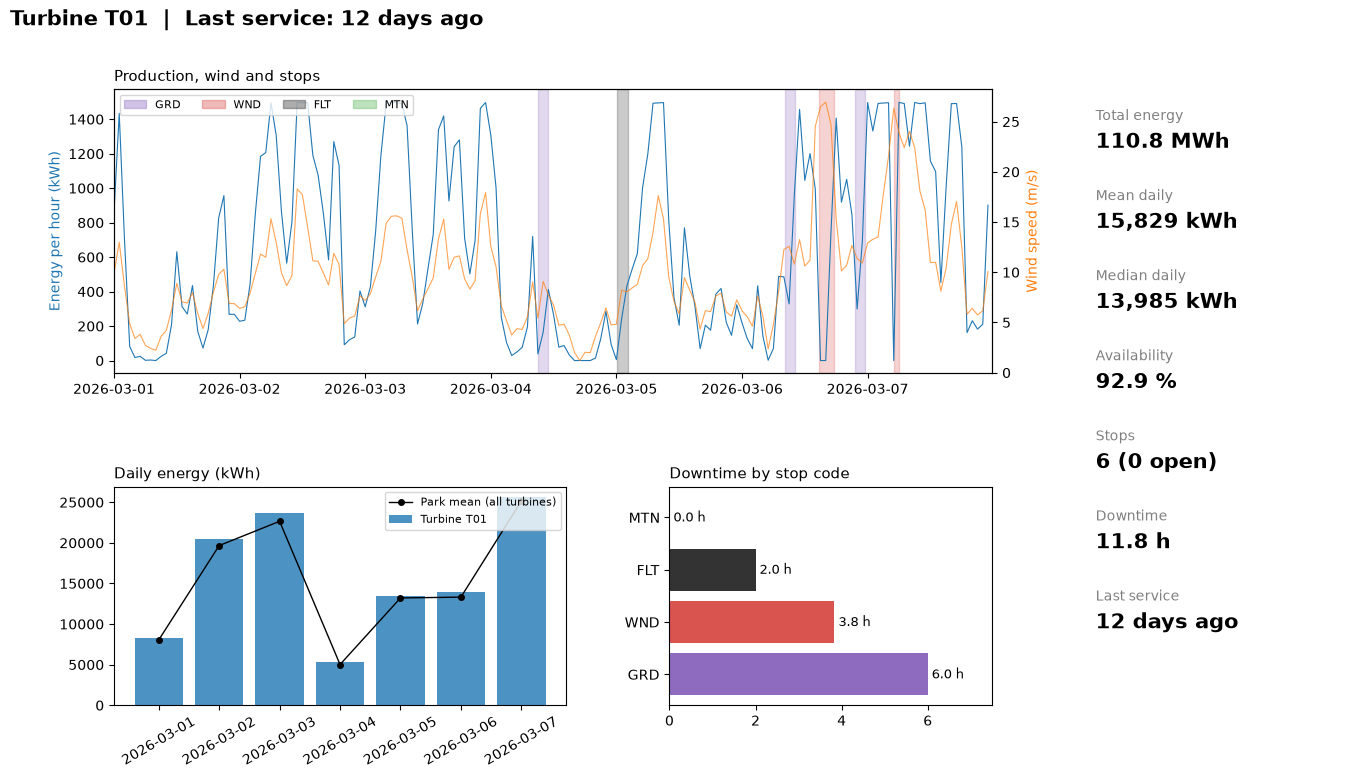

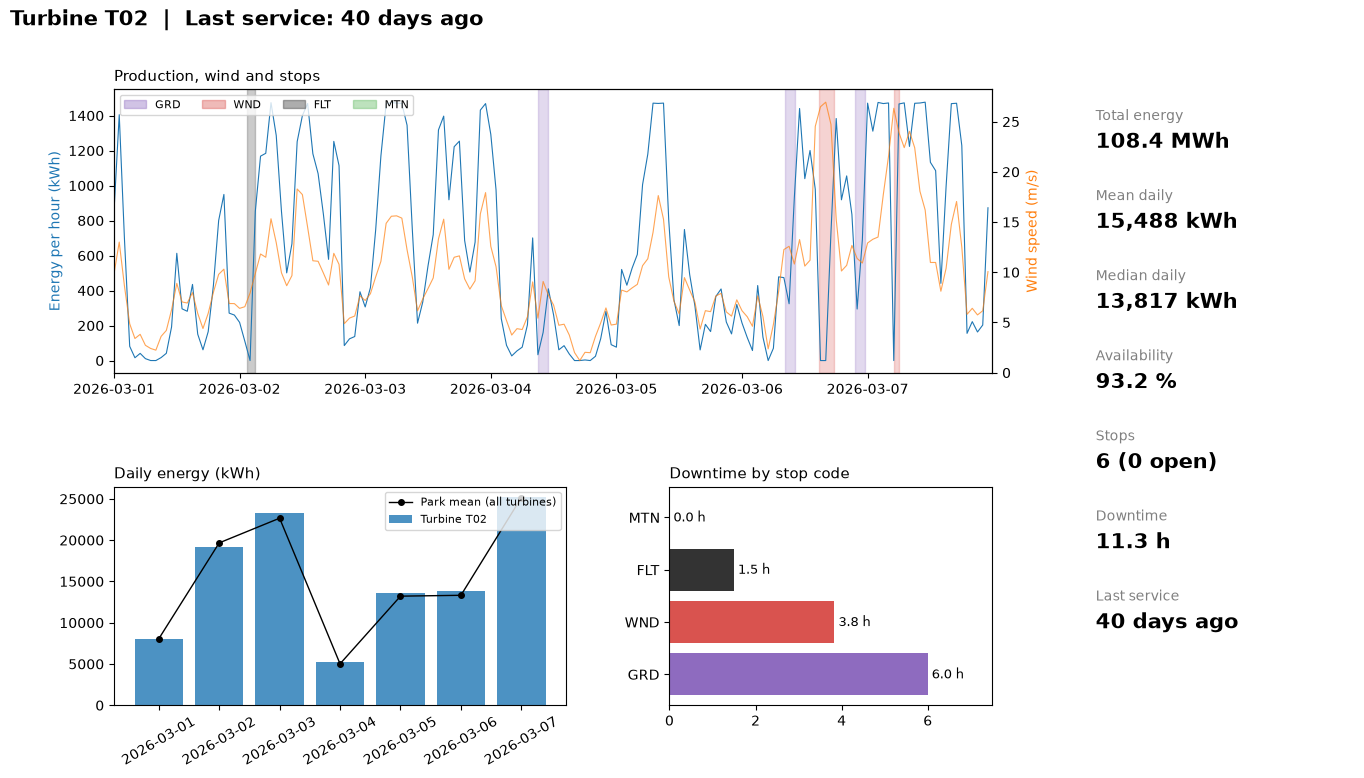

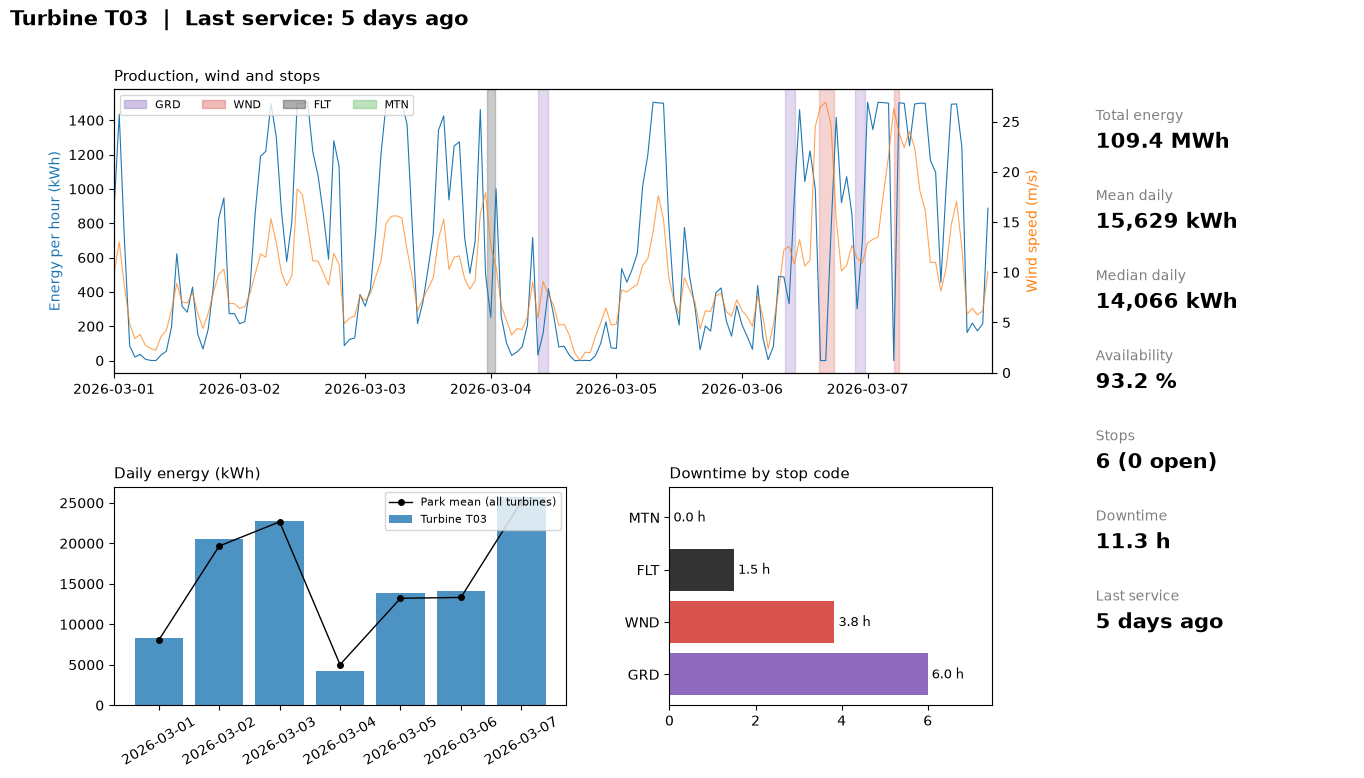

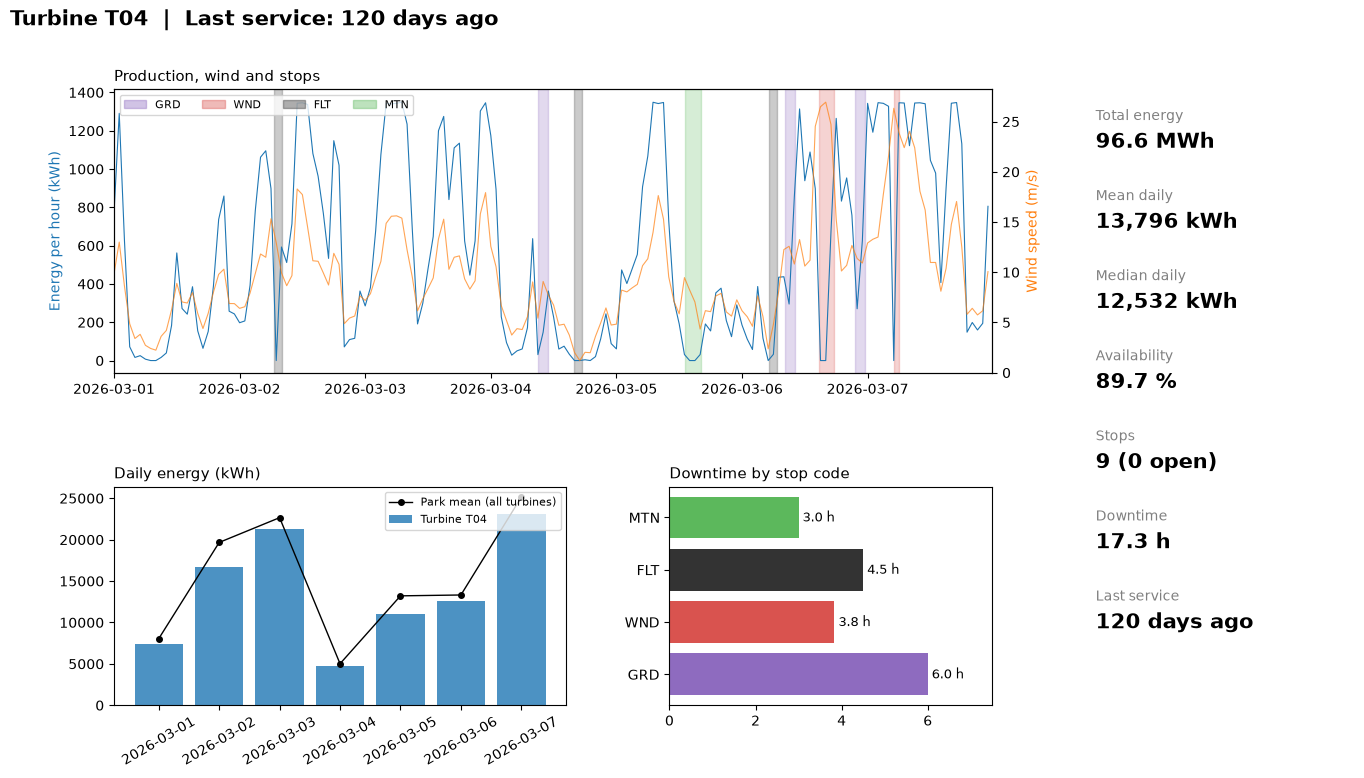

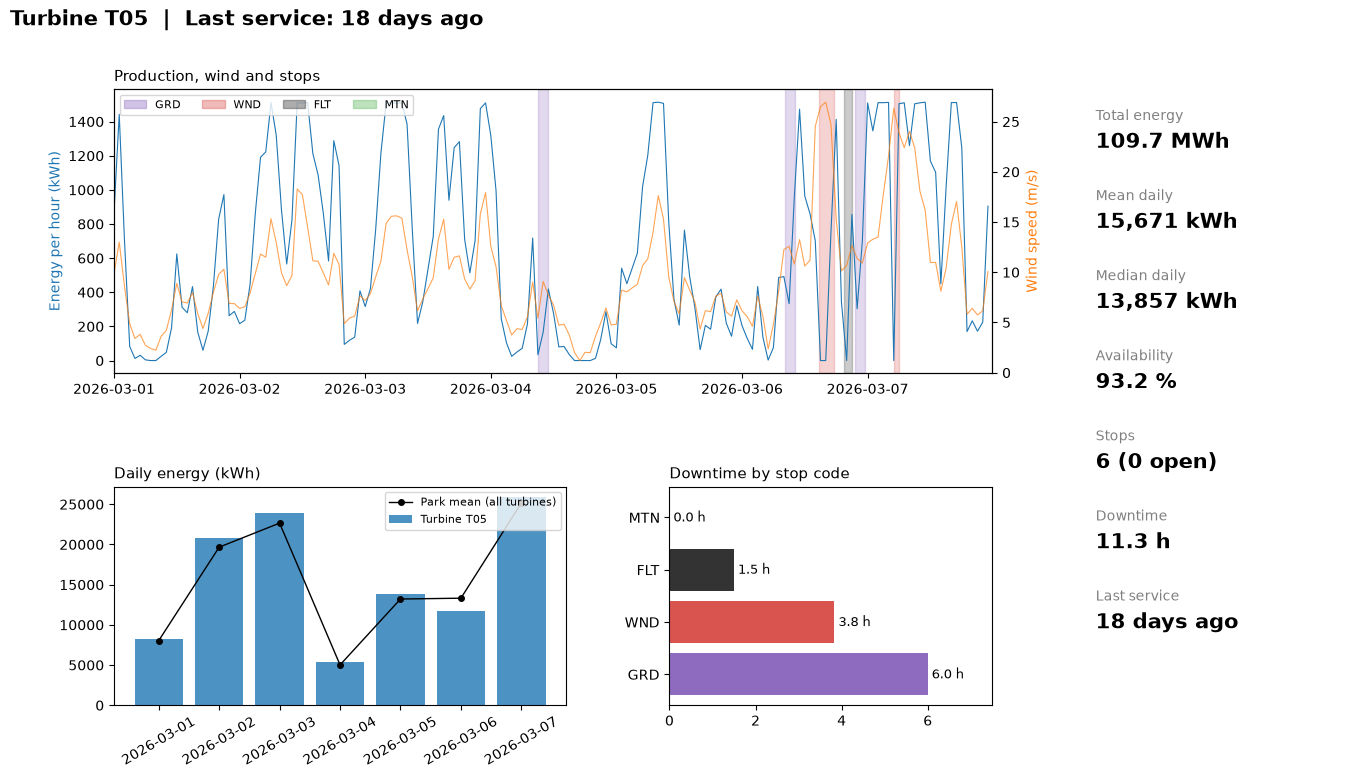

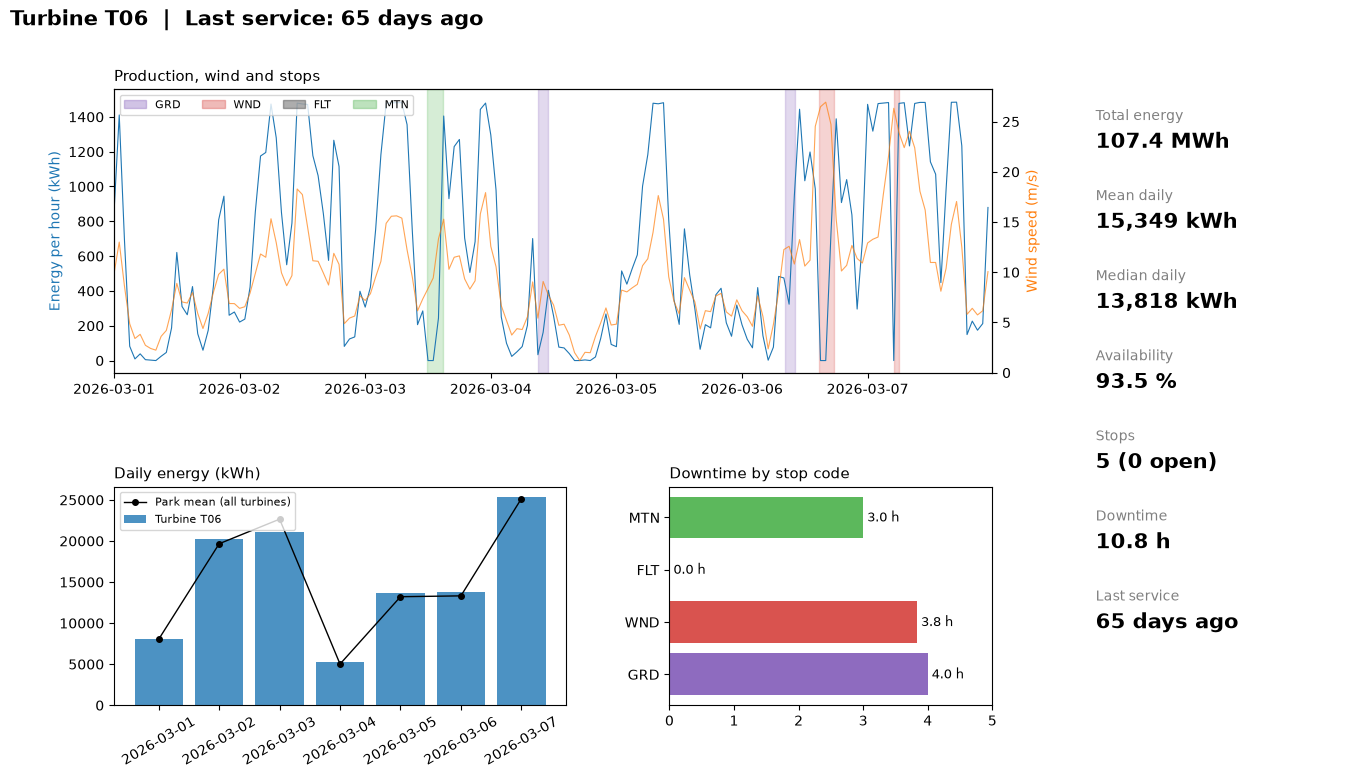

In [49]:
wind_h = df_weather.set_index("timestamp")["wind_speed_ms"].sort_index().resample("1h").mean()

def turbine_card(tid):
    row = summary.set_index("turbine_id").loc[tid]
    prod_h = (df_prod[df_prod["turbine_id"] == tid].set_index("timestamp")["energy_kwh"]
              .sort_index().resample("1h").sum())
    s = stops[stops["turbine_id"] == tid]
    d = daily[daily["turbine_id"] == tid]
    park_daily_median = daily.groupby("timestamp")["energy_kwh"].median()
    park_daily_mean = daily.groupby("timestamp")["energy_kwh"].mean()

    fig = plt.figure(figsize=(16, 8))
    gs = GridSpec(2, 3, figure=fig, width_ratios=[1.4, 1, 0.8], height_ratios=[1.3, 1],
                  hspace=0.45, wspace=0.3)

    ax = fig.add_subplot(gs[0, :2])
    ax.plot(prod_h.index, prod_h.values, color="tab:blue", linewidth=0.8)
    ax.set_ylabel("Energy per hour (kWh)", color="tab:blue")
    for _, r in s.iterrows():
        ax.axvspan(r["start_c"], r["end_c"], color=STOP_COLORS.get(r["stop_code"], "grey"), alpha=0.25)
    axw = ax.twinx()
    axw.plot(wind_h.index, wind_h.values, color="tab:orange", linewidth=0.8, alpha=0.7)
    axw.set_ylabel("Wind speed (m/s)", color="tab:orange")
    axw.grid(False)
    ax.set_xlim(PERIOD_START, PERIOD_END)
    ax.set_title("Production, wind and stops", loc="left", fontsize=11)
    ax.legend(handles=[Patch(color=c, alpha=0.4, label=k) for k, c in STOP_COLORS.items()],
              loc="upper left", ncol=4, fontsize=8)

    ax_d = fig.add_subplot(gs[1, 0])
    ax_d.bar(d["timestamp"], d["energy_kwh"], width=0.8, color="tab:blue", alpha=0.8, label=f"Turbine {tid}")
    ax_d.plot(park_daily_mean.index, park_daily_mean.values, color="black",
              marker="o", markersize=4, linewidth=1, label="Park mean (all turbines)")
    ax_d.set_title("Daily energy (kWh)", loc="left", fontsize=11)
    ax_d.legend(fontsize=8)
    ax_d.tick_params(axis="x", rotation=30)


    ax_c = fig.add_subplot(gs[1, 1])
    hours = [row[f"{c}_h"] for c in STOP_COLORS]
    ax_c.barh(list(STOP_COLORS), hours, color=list(STOP_COLORS.values()))
    for y, h in enumerate(hours):
        ax_c.text(h, y, f" {h:.1f} h", va="center", fontsize=9)
    ax_c.set_title("Downtime by stop code", loc="left", fontsize=11)
    ax_c.set_xlim(0, max(max(hours) * 1.25, 1))

    ax_k = fig.add_subplot(gs[:, 2])
    ax_k.axis("off")
    service = (f"{int(row['last_service_days_ago'])} days ago"
               if pd.notna(row.get("last_service_days_ago")) else "unknown")
    kpis = [
        ("Total energy", f"{row['total_mwh']:.1f} MWh"),
        ("Mean daily", f"{row['mean_daily_kwh']:,.0f} kWh"),
        ("Median daily", f"{row['median_daily_kwh']:,.0f} kWh"),
        ("Availability", f"{row['availability_%']:.1f} %"),
        ("Stops", f"{int(row['n_stops'])} ({int(row['open_stops'])} open)"),
        ("Downtime", f"{row['downtime_h']:.1f} h"),
        ("Last service", service),
    ]
    y = 0.95
    for label, value in kpis:
        ax_k.text(0, y, label, fontsize=10, color="grey", transform=ax_k.transAxes)
        ax_k.text(0, y - 0.045, value, fontsize=15, weight="bold", transform=ax_k.transAxes)
        y -= 0.13

    fig.suptitle(f"Turbine {tid}  |  Last service: {service}",
                 x=0.06, ha="left", fontsize=15, weight="bold")
    plt.show()


for tid in summary.sort_values("turbine_id")["turbine_id"]:
    turbine_card(tid)

In [50]:
def during_stop(i, margin="1h"):
    """Production and weather around stop number i (with a margin before and after)."""
    stop = df_stops.loc[i]
    start = stop["timestamp_start"] - pd.Timedelta(margin)
    end = (stop["timestamp_end"] if pd.notna(stop["timestamp_end"]) else df_prod["timestamp"].max()) + pd.Timedelta(margin)

    prod = df_prod[(df_prod["turbine_id"] == stop["turbine_id"]) &
                   (df_prod["timestamp"].between(start, end))]
    weather = df_weather[df_weather["timestamp"].between(start, end)]

    print(stop[["turbine_id", "stop_code", "timestamp_start", "timestamp_end", "comment"]], "\n")
    return prod.merge(weather, on="timestamp", how="left")

during_stop(0)

turbine_id                                  T02
stop_code                                   FLT
timestamp_start             2026-03-02 01:30:00
timestamp_end               2026-03-02 03:00:00
comment            Hydraulic technical fault #1
Name: 0, dtype: object 



,timestamp,turbine_id,energy_kwh,wind_speed_ms
0,2026-03-02 00:30:00,T02,33.09,6.41
1,2026-03-02 00:40:00,T02,17.60,4.98
2,2026-03-02 00:50:00,T02,23.30,5.67
3,2026-03-02 01:00:00,T02,30.03,6.12
4,2026-03-02 01:10:00,T02,37.40,6.50
5,2026-03-02 01:20:00,T02,42.90,7.00
6,2026-03-02 01:30:00,T02,0.00,6.22
7,2026-03-02 01:40:00,T02,0.00,6.58
8,2026-03-02 01:50:00,T02,0.00,7.00
9,2026-03-02 02:00:00,T02,0.00,6.18


In [53]:
duckdb.sql("""
    SELECT turbine_id,
           stop_code,
           COUNT(*) AS n_stops,
           SUM(date_diff('minute', timestamp_start, timestamp_end)) / 60.0 AS total_hours
    FROM df_stops
    GROUP BY turbine_id, stop_code
    ORDER BY total_hours DESC
""").df() 

,turbine_id,stop_code,n_stops,total_hours
0,T05,GRD,3,6.000000
1,T02,GRD,3,6.000000
2,T03,GRD,3,6.000000
3,T04,GRD,3,6.000000
4,T01,GRD,3,6.000000
5,T04,FLT,3,4.500000
6,T06,GRD,2,4.000000
7,T05,WND,2,3.833333
8,T01,WND,2,3.833333
9,T02,WND,2,3.833333


## Park level performance

In [54]:
df_park_stops = df_stops[df_stops["stop_code"].isin(["GRD", "WND"])]

In [55]:
selected_stops = df_park_stops.drop_duplicates(subset="timestamp_start")

In [56]:
selected_stops

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
4,2026-03-04 09:00:00,2026-03-04 11:00:00,T01,GRD,Park-level grid limitation
14,2026-03-06 08:10:00,2026-03-06 10:10:00,T01,GRD,Park-level grid limitation
20,2026-03-06 14:40:00,2026-03-06 17:30:00,T01,WND,High wind shutdown
27,2026-03-06 21:30:00,2026-03-06 23:30:00,T01,GRD,Park-level grid limitation
32,2026-03-07 05:00:00,2026-03-07 06:00:00,T01,WND,High wind shutdown


In park level, there were 5 stops:
- 3 due to grid limitation
- 2 due high wind

These would be the external losses, that we cannot control. The reasons may be that the energy supply is higher than we need (can be during high wind) or external problems.

GRD: 3 stops


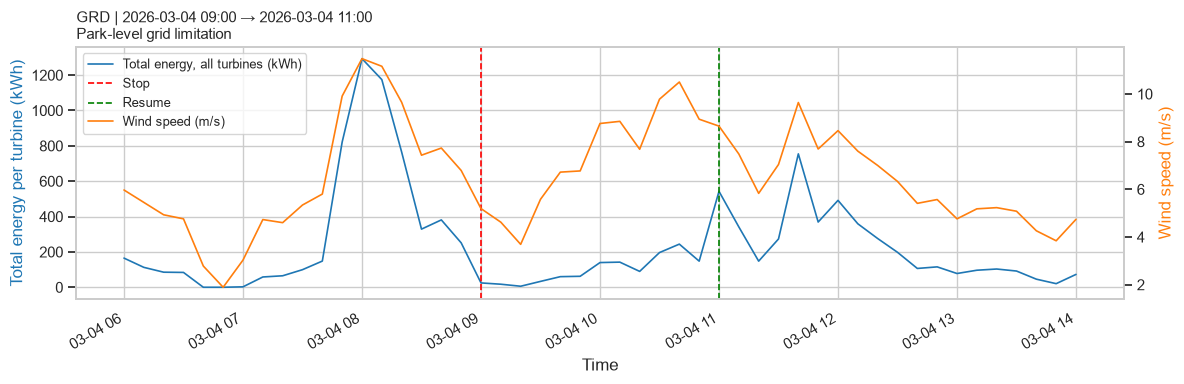

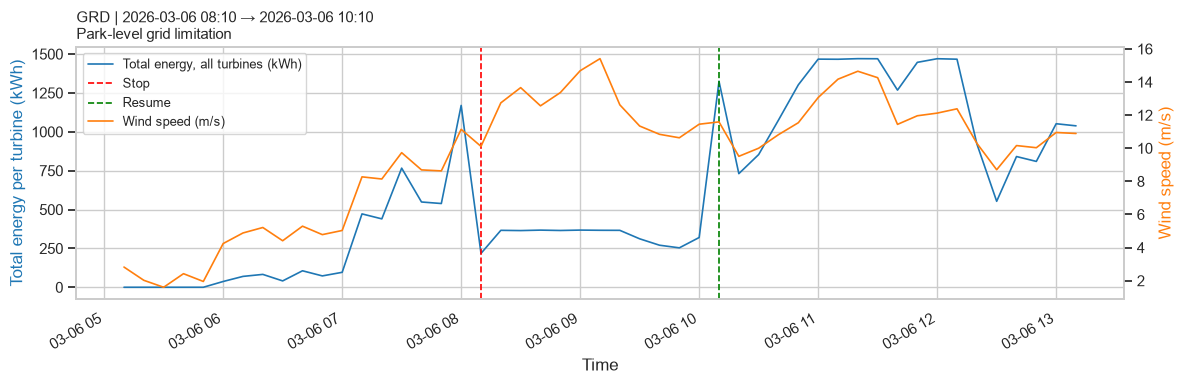

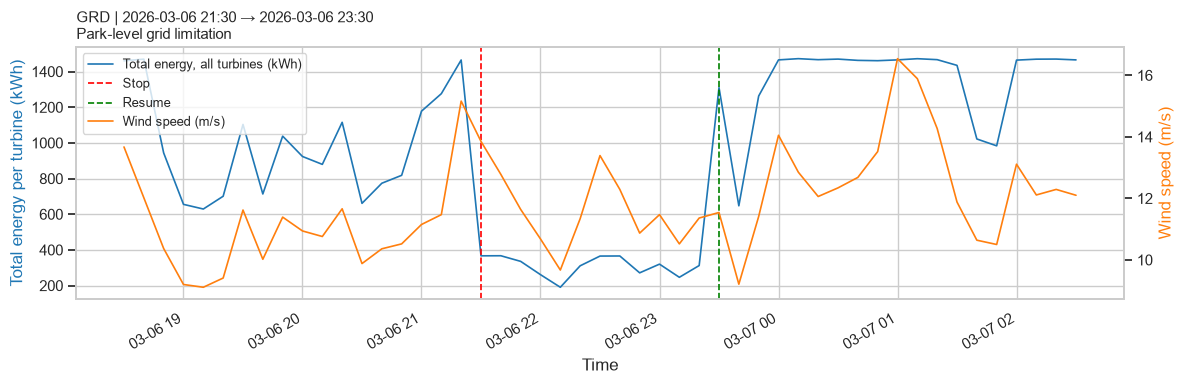

WND: 2 stops


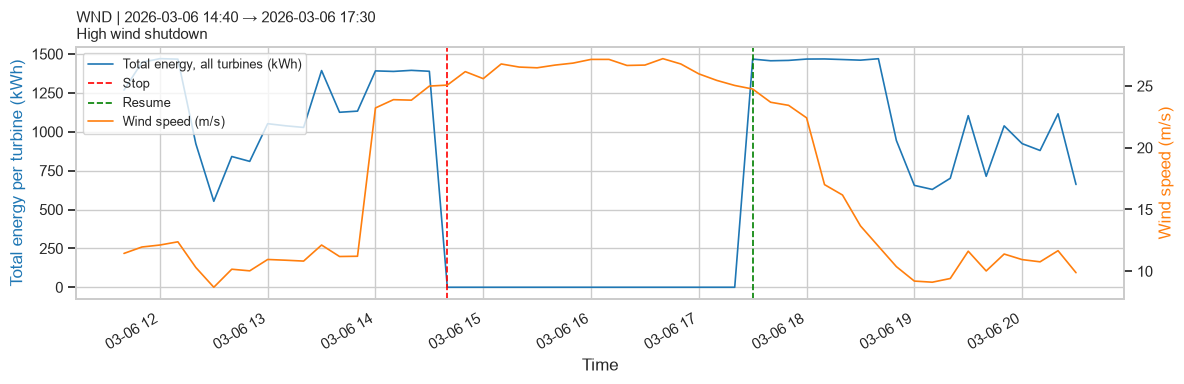

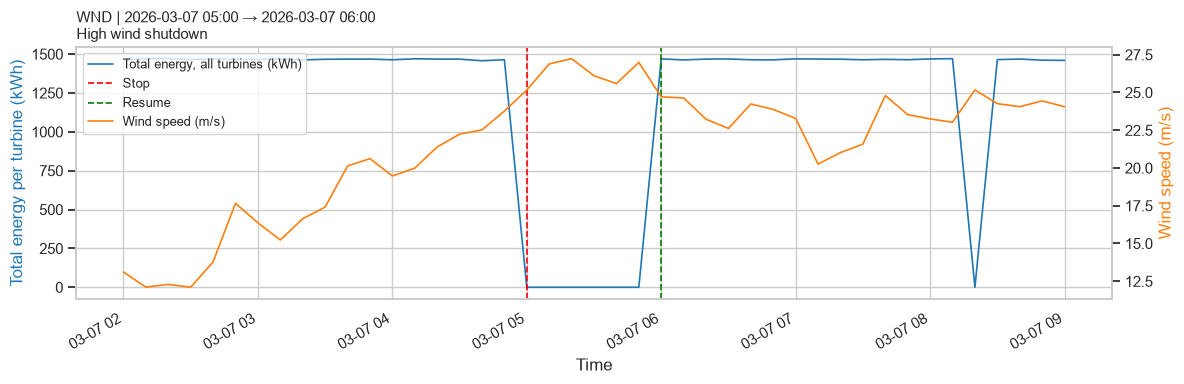

In [57]:
def plot_stop(stop, margin=pd.Timedelta("3h")):
    start = stop["timestamp_start"]
    end = stop["timestamp_end"]
    window_end = (end if pd.notna(end) else start + pd.Timedelta("1D")) + margin
    window_start = start - margin

    prod = (df_prod[df_prod["timestamp"].between(window_start, window_end)]
                   .groupby("timestamp", as_index=False)["energy_kwh"].sum())
    wind = df_weather[df_weather["timestamp"].between(window_start, window_end)]

    fig, ax1 = plt.subplots(figsize=(12, 4))
    ax1.plot(prod["timestamp"], prod["energy_kwh"], color="tab:blue", linewidth=1.2,
             label="Total energy, all turbines (kWh)")
    ax1.set_ylabel("Total energy per turbine (kWh)", color="tab:blue")

    ax2 = ax1.twinx()
    ax2.plot(wind["timestamp"], wind["wind_speed_ms"], color="tab:orange", linewidth=1.2, label="Wind speed (m/s)")
    ax2.set_ylabel("Wind speed (m/s)", color="tab:orange")
    ax2.grid(False)

    ax1.axvline(start, color="red", linestyle="--", linewidth=1.2, label="Stop")
    if pd.notna(end):
        ax1.axvline(end, color="green", linestyle="--", linewidth=1.2, label="Resume")

    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)

    end_txt = end.strftime("%Y-%m-%d %H:%M") if pd.notna(end) else "no end time"
    ax1.set_title(f"{stop['stop_code']} | {start:%Y-%m-%d %H:%M} → {end_txt}\n{stop['comment']}",
                  fontsize=11, loc="left")
    ax1.set_xlabel("Time")
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()


for code in ["GRD", "WND"]:
    subset = selected_stops[selected_stops["stop_code"] == code].sort_values("timestamp_start")
    print(f"{code}: {len(subset)} stops")
    for _, stop in subset.iterrows():
        plot_stop(stop)

What's the wind speed threshold for shutting down turbines?

In [58]:
selected_stops

,timestamp_start,timestamp_end,turbine_id,stop_code,comment
4,2026-03-04 09:00:00,2026-03-04 11:00:00,T01,GRD,Park-level grid limitation
14,2026-03-06 08:10:00,2026-03-06 10:10:00,T01,GRD,Park-level grid limitation
20,2026-03-06 14:40:00,2026-03-06 17:30:00,T01,WND,High wind shutdown
27,2026-03-06 21:30:00,2026-03-06 23:30:00,T01,GRD,Park-level grid limitation
32,2026-03-07 05:00:00,2026-03-07 06:00:00,T01,WND,High wind shutdown


In [59]:
df_weather

,timestamp,wind_speed_ms
0,2026-03-01 00:00:00,8.33
1,2026-03-01 00:10:00,9.00
2,2026-03-01 00:20:00,8.78
3,2026-03-01 00:30:00,9.67
4,2026-03-01 00:40:00,11.85
...,...,...
1003,2026-03-07 23:10:00,9.86
1004,2026-03-07 23:20:00,8.89
1005,2026-03-07 23:30:00,9.85
1006,2026-03-07 23:40:00,10.35


In [61]:
duckdb.sql("""
    SELECT s.timestamp_start,
           s.timestamp_end,
           s.stop_code,
           arg_min(w.wind_speed_ms, w.timestamp) AS wind_at_start,
           arg_max(w.wind_speed_ms, w.timestamp) AS wind_at_end,
           MIN(w.wind_speed_ms)                  AS wind_min,
           MAX(w.wind_speed_ms)                  AS wind_max
    FROM selected_stops AS s
    LEFT JOIN df_weather AS w
           ON w.timestamp BETWEEN s.timestamp_start AND s.timestamp_end
    GROUP BY s.timestamp_start, s.timestamp_end, s.stop_code
    ORDER BY s.stop_code, s.timestamp_start
""").df()

,timestamp_start,timestamp_end,stop_code,wind_at_start,wind_at_end,wind_min,wind_max
0,2026-03-04 09:00:00,2026-03-04 11:00:00,GRD,5.19,8.65,3.69,10.50
1,2026-03-06 08:10:00,2026-03-06 10:10:00,GRD,10.11,11.59,10.11,15.41
2,2026-03-06 21:30:00,2026-03-06 23:30:00,GRD,13.85,11.54,9.67,13.85
3,2026-03-06 14:40:00,2026-03-06 17:30:00,WND,25.07,24.75,24.75,27.21
4,2026-03-07 05:00:00,2026-03-07 06:00:00,WND,25.16,24.71,24.71,27.24


Has the wind been > 25 m/s where the stop hasn't been recorded?

In [62]:
duckdb.sql("""
    SELECT w.timestamp, w.wind_speed_ms
    FROM df_weather AS w
    WHERE w.wind_speed_ms > 25
      AND NOT EXISTS (
          SELECT 1
          FROM selected_stops AS s
          WHERE s.stop_code = 'WND'
            AND w.timestamp BETWEEN s.timestamp_start
                                AND COALESCE(s.timestamp_end, s.timestamp_start + INTERVAL 1 DAY)
      )
    ORDER BY w.timestamp
""").df()

,timestamp,wind_speed_ms
0,2026-03-07 08:20:00,25.17


The whole park is shut down when the wind is >25 m/s for more than 10 mins.